In [1]:

import os
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

work_path = Path.cwd()

if (work_path / "data").exists():
    main_path = work_path
else:
    main_path = work_path.parent

data_path = main_path / "data" / "loan_approval_dataset.csv"
img_path = main_path / "images"
save_path = main_path / "models"

img_path.mkdir(parents=True, exist_ok=True)
save_path.mkdir(parents=True, exist_ok=True)

loan_df = pd.read_csv(data_path)

loan_df.columns = loan_df.columns.str.strip()

for col_name in ["education", "self_employed", "loan_status"]:
    loan_df[col_name] = loan_df[col_name].astype(str).str.strip()

loan_df.drop(columns=["loan_id"], errors="ignore", inplace=True)

loan_df["loan_status"] = loan_df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

loan_df["education"] = loan_df["education"].map({
    "Graduate": 1,
    "Not Graduate": 0
})

loan_df["self_employed"] = loan_df["self_employed"].map({
    "Yes": 1,
    "No": 0
})

print("Dataset Shape:", loan_df.shape)
print("\nMissing Values:\n", loan_df.isnull().sum())
print("\nDuplicate Records:", loan_df.duplicated().sum())
print("\nLoan Status:\n", loan_df["loan_status"].value_counts())

if loan_df.isnull().sum().sum() > 0:
    raise ValueError("Missing values found in dataset")

print("\nDataset loaded successfully!")


Dataset Shape: (4269, 12)

Missing Values:
 no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate Records: 0

Loan Status:
 loan_status
1    2656
0    1613
Name: count, dtype: int64

Dataset loaded successfully!


C:\Users\ak251\AppData\Local\Temp\ipykernel_28480\1628918523.py:28: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  loan_df.drop(columns=["loan_id"], errors="ignore", inplace=True)


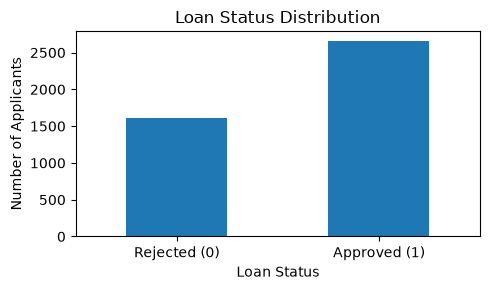

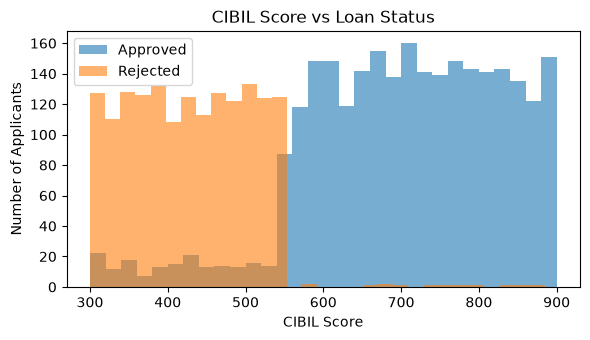

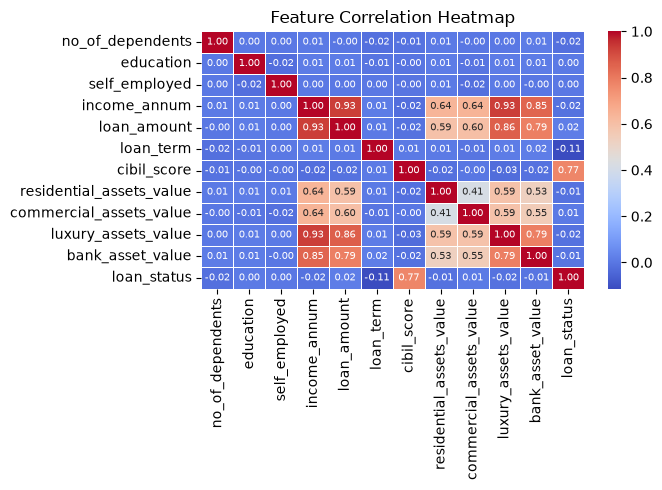

Approval Rate by Education:
education
0    0.620
1    0.625
Name: loan_status, dtype: float64

Approval Rate by Self Employment:
self_employed
0    0.622
1    0.622
Name: loan_status, dtype: float64

EDA completed successfully!


In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 3))

status_data = loan_df["loan_status"].value_counts().reindex([0, 1])

status_data.plot(kind="bar")

plt.title("Loan Status Distribution")
plt.xticks([0, 1], ["Rejected (0)", "Approved (1)"], rotation=0)
plt.ylabel("Number of Applicants")
plt.xlabel("Loan Status")

plt.tight_layout()
plt.savefig(img_path / "plot1_class_distribution.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close()


plt.figure(figsize=(6, 3.5))

plt.hist(
    loan_df[loan_df["loan_status"] == 1]["cibil_score"],
    bins=30,
    alpha=0.6,
    label="Approved"
)

plt.hist(
    loan_df[loan_df["loan_status"] == 0]["cibil_score"],
    bins=30,
    alpha=0.6,
    label="Rejected"
)

plt.xlabel("CIBIL Score")
plt.ylabel("Number of Applicants")
plt.title("CIBIL Score vs Loan Status")
plt.legend()

plt.tight_layout()
plt.savefig(img_path / "plot2_cibil_vs_status.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close()


plt.figure(figsize=(7, 5))

sns.heatmap(
    loan_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.4,
    annot_kws={"size": 7}
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig(img_path / "plot3_heatmap.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close()


print("Approval Rate by Education:")
print(loan_df.groupby("education")["loan_status"].mean().round(3))

print("\nApproval Rate by Self Employment:")
print(loan_df.groupby("self_employed")["loan_status"].mean().round(3))

print("\nEDA completed successfully!")


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

input_features = loan_df.drop("loan_status", axis=1)
output_target = loan_df["loan_status"]

feature_list = input_features.columns.tolist()

x_train, x_test, y_train, y_test = train_test_split(
    input_features,
    output_target,
    test_size=0.2,
    random_state=42,
    stratify=output_target
)

scale_tool = StandardScaler()

x_train_scaled = scale_tool.fit_transform(x_train)
x_test_scaled = scale_tool.transform(x_test)

ml_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

for model_name, model_obj in ml_models.items():

    if model_name == "Logistic Regression":
        model_obj.fit(x_train_scaled, y_train)
        model_predictions = model_obj.predict(x_test_scaled)
    else:
        model_obj.fit(x_train, y_train)
        model_predictions = model_obj.predict(x_test)

    print("\n", "=" * 45)
    print(model_name)

    print("Accuracy:",
          round(accuracy_score(y_test, model_predictions), 4))

    print("\nClassification Report:")

    print(classification_report(
        y_test,
        model_predictions,
        target_names=["Rejected", "Approved"]
    ))

print("\nAll models trained successfully!")



Logistic Regression
Accuracy: 0.9133

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.90      0.87      0.88       323
    Approved       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854


Decision Tree
Accuracy: 0.9813

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.98      0.98      0.98       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Random Forest
Accuracy: 0.9801

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.98      0.97      0.97       323
    Approved       0.98      0.98      0.98       531

    accu

c:\Users\ak251\loan-approval-xai\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.9133,0.9208,0.9416,0.9311,0.9726
Decision Tree,0.9813,0.9849,0.9849,0.9849,0.9801
Random Forest,0.9801,0.9831,0.9849,0.9840,0.9989


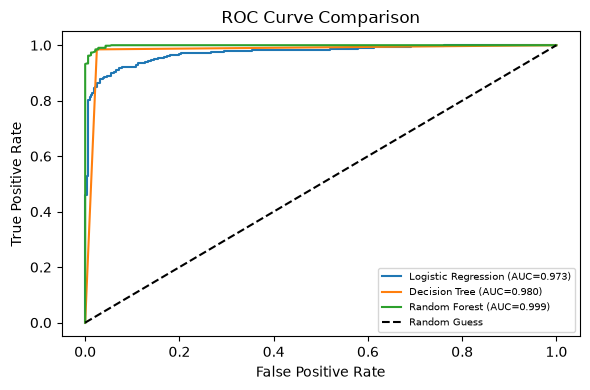

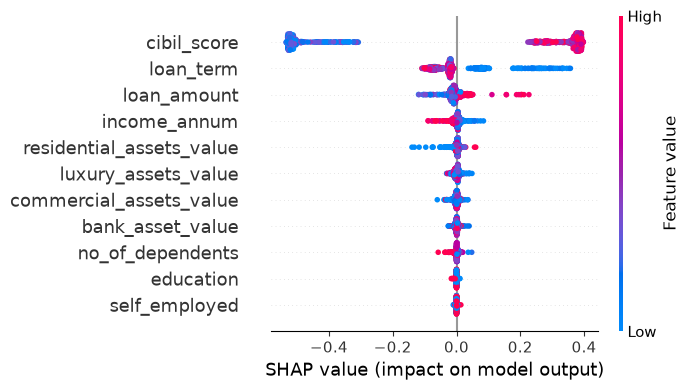

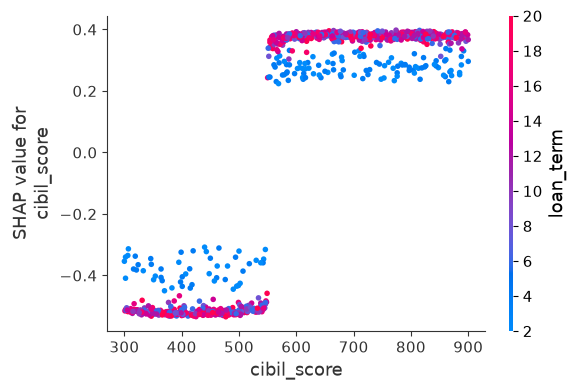


Model comparison and SHAP analysis completed!


In [4]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

import shap

model_results = []

for model_name, model_obj in ml_models.items():

    if model_name == "Logistic Regression":
        test_data = x_test_scaled
    else:
        test_data = x_test

    predicted_values = model_obj.predict(test_data)
    predicted_probs = model_obj.predict_proba(test_data)[:, 1]

    model_results.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, predicted_values), 4),
        "Precision": round(precision_score(y_test, predicted_values), 4),
        "Recall": round(recall_score(y_test, predicted_values), 4),
        "F1": round(f1_score(y_test, predicted_values), 4),
        "ROC-AUC": round(roc_auc_score(y_test, predicted_probs), 4)
    })

comparison_table = pd.DataFrame(model_results).set_index("Model")

display(comparison_table)


plt.figure(figsize=(6, 4))

for model_name, model_obj in ml_models.items():

    if model_name == "Logistic Regression":
        test_data = x_test_scaled
    else:
        test_data = x_test

    predicted_probs = model_obj.predict_proba(test_data)[:, 1]

    false_positive, true_positive, thresholds = roc_curve(
        y_test,
        predicted_probs
    )

    area_score = roc_auc_score(y_test, predicted_probs)

    plt.plot(
        false_positive,
        true_positive,
        label=f"{model_name} (AUC={area_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(fontsize=7)

plt.tight_layout()
plt.savefig(img_path / "plot4_roc_curves.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close()


tree_explainer = shap.TreeExplainer(ml_models["Random Forest"])
shap_output = tree_explainer.shap_values(x_test)

if isinstance(shap_output, list):
    approval_shap = shap_output[1]
elif isinstance(shap_output, np.ndarray) and shap_output.ndim == 3:
    approval_shap = shap_output[:, :, 1]
else:
    approval_shap = shap_output

shap.summary_plot(
    approval_shap,
    x_test,
    show=False,
    plot_size=(7, 4)
)

plt.tight_layout()
plt.savefig(img_path / "plot5_shap_summary.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close()


shap.dependence_plot(
    "cibil_score",
    approval_shap,
    x_test,
    show=False
)

plt.gcf().set_size_inches(6, 4)
plt.tight_layout()

plt.savefig(img_path / "plot6_shap_cibil.png", bbox_inches="tight", dpi=300)

plt.show()
plt.close()

print("\nModel comparison and SHAP analysis completed!")


In [5]:

model_data = {
    "models": ml_models,
    "scaler": scale_tool,
    "feature_names": feature_list
}

joblib.dump(
    model_data,
    save_path / "all_models.pkl"
)

joblib.dump(
    ml_models["Random Forest"],
    save_path / "random_forest_model.pkl"
)

joblib.dump(
    scale_tool,
    save_path / "scaler.pkl"
)

print("All models saved successfully!")

for saved_file in save_path.iterdir():
    print(saved_file.name)


All models saved successfully!
all_models.pkl
random_forest_model.pkl
README.md
scaler.pkl


In [6]:

print("Project Location:", main_path)

print("\nDataset:")
print(data_path.exists())

print("\nGenerated Images:")

for image_file in img_path.iterdir():
    print(image_file.name)

print("\nSaved Models:")

for model_file in save_path.iterdir():
    print(model_file.name)

print("\nProject execution completed successfully!")


Project Location: c:\Users\ak251\loan-approval-xai

Dataset:
True

Generated Images:
plot1_class_distribution.png
plot2_cibil_vs_status.png
plot3_heatmap.png
plot4_roc_curves.png
plot5_shap_summary.png
plot6_shap_cibil.png

Saved Models:
all_models.pkl
random_forest_model.pkl
README.md
scaler.pkl

Project execution completed successfully!
